# Correlation: Targets and Receiving Yards

How strongly are targets per game and receiving yards per game related?

In [26]:
import pandas as pd

# Load the CSV into a DataFrame: a table with named columns.
players = pd.read_csv("../data/stats_player_week_2026.csv")

# .loc[rows, columns] selects which rows and columns to keep.
# == compares values: keep rows whose position is "WR".
receivers = players.loc[
    players["position"] == "WR",
    ["player_display_name", "week", "targets", "receptions", "receiving_yards"],
]

# .groupby() gathers rows belonging to the same player.
# as_index=False keeps player names as a regular column.
# .agg() calculates summaries for each player's group.
# Each entry follows: new_column=("source_column", "operation").
receiver_per_game = receivers.groupby(
    "player_display_name",
    as_index=False,
).agg(
    games_recorded=("week", "size"),  # Count recorded rows.
    total_targets=("targets", "sum"),  # Add weekly targets.
    total_yards=("receiving_yards", "sum"),  # Add weekly yards.
)

# Selecting a column with ["column_name"] returns a Series.
# Dividing two Series calculates a result for each matching row.
# Assigning to a new column name adds that column to the table.
receiver_per_game["targets_per_game"] = (
    receiver_per_game["total_targets"] / receiver_per_game["games_recorded"]
)

receiver_per_game["yards_per_game"] = (
    receiver_per_game["total_yards"] / receiver_per_game["games_recorded"]
)

# .head() displays the first five rows; it does not sort them.
receiver_per_game.head()

,player_display_name,games_recorded,total_targets,total_yards,targets_per_game,yards_per_game
0,A.J. Brown,2,14,53,7.0,26.5
1,Adonai Mitchell,2,15,123,7.5,61.5
2,Alec Pierce,2,7,72,3.5,36.0
3,Alex Bachman,3,0,0,0.0,0.0
4,Amon-Ra St. Brown,5,57,372,11.4,74.4


In [27]:
# .corr() measures the relationship between two numerical columns.
# Pearson correlation ranges from -1 to +1:
# -1 = perfect downward line; +1 = perfect upward line.
# Near 0 means little linear relationship.
# Missing pairs are excluded from the calculation.
correlation = receiver_per_game["targets_per_game"].corr(
    receiver_per_game["yards_per_game"],
    method="pearson",
)

correlation

np.float64(0.9148870571765839)

In [28]:
# Keep receivers with at least 20 total targets.
# This is a practice cutoff, not a guarantee of reliable results.
qualified_receivers = receiver_per_game.loc[
    receiver_per_game["total_targets"] >= 20
]

# Calculate Pearson correlation for this smaller group.
qualified_correlation = qualified_receivers["targets_per_game"].corr(
    qualified_receivers["yards_per_game"],
    method="pearson",
)

# Display both results so we can compare them.
print("All receivers:", correlation)
print("At least 20 targets:", qualified_correlation)

All receivers: 0.9148870571765839
At least 20 targets: 0.8192766079219042


## Findings

- All receivers: Pearson correlation ≈ 0.91.
- Receivers with at least 20 targets: Pearson correlation ≈ 0.81.
- Both groups show a strong positive linear relationship between
  targets per recorded game and receiving yards per recorded game.
- The result depends on which receivers are included.
- Correlation alone does not establish causation.

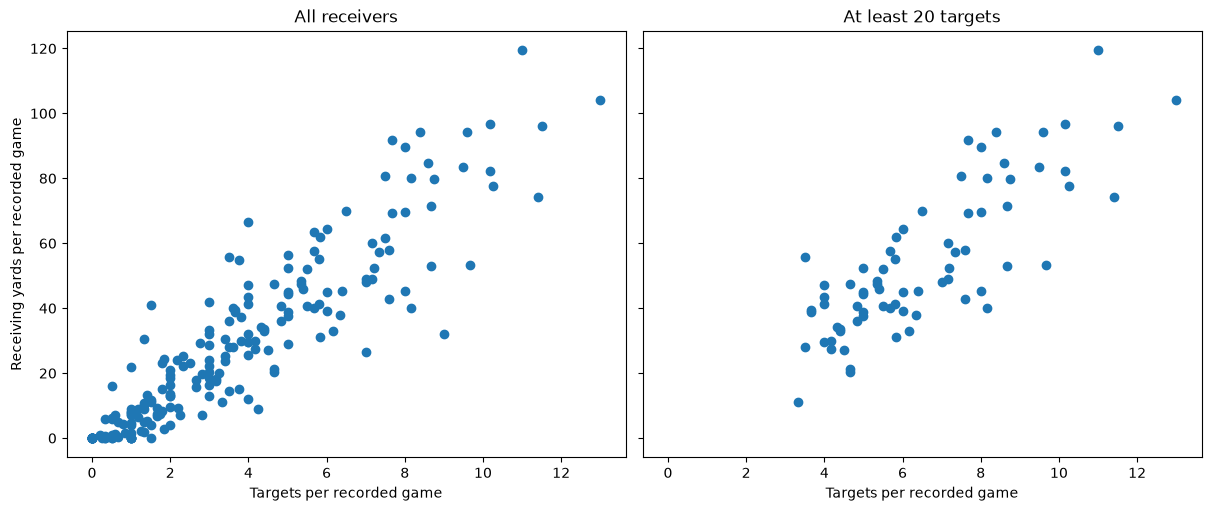

In [29]:
import matplotlib.pyplot as plt

# fig is the figure object, axes is a list of Axes objects (one for each plot).
# Create one figure containing two plots: 1 row and 2 columns.
# Share axis scales so distances mean the same thing in both plots.
# layout="constrained" automatically makes room for labels.
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharex=True,
    sharey=True,
    layout="constrained",
)

# axes[0] selects the left plot.
# Each dot represents one receiver.
axes[0].scatter(
    receiver_per_game["targets_per_game"],
    receiver_per_game["yards_per_game"],
)
axes[0].set_title("All receivers")

# axes[1] selects the right plot.
# Show only receivers with at least 20 total targets.
axes[1].scatter(
    qualified_receivers["targets_per_game"],
    qualified_receivers["yards_per_game"],
)
axes[1].set_title("At least 20 targets")

# Apply the same horizontal label to both plots.
for ax in axes:
    ax.set_xlabel("Targets per recorded game")

# Both plots share the vertical scale, so label it on the left.
axes[0].set_ylabel("Receiving yards per recorded game")

plt.show()

Filtering to at least 20 total targets removed many receivers with
low targets per recorded game. The filtered group covered a narrower
range of values and had a lower correlation.